# GeoGen AI — Clean Training Notebook

This notebook preserves the full training workflow. The original notebook is unchanged.

- Run cells from top to bottom when you are ready to train.
- Training starts only when you manually run the training cell in Section 7.
- The model is saved to `artifacts/staging/checkpoints/`, not the live website checkpoint.
- To train to a different total epoch count, change `TOTAL_TARGET_EPOCHS` in Section 5 (for example, 50, 60, or 100).
- The notebook resumes from a valid staged checkpoint when optimizer state is available; the original live checkpoint is read-only.
- Dataset preparation is handled in one section. Repeated extraction and exploratory testing cells have been removed.
- This cleanup does not train the model or change any saved checkpoint.


## 1. Mount Drive and set project paths

In [5]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive')
PROJECT_CANDIDATES = [
    DRIVE_ROOT / 'GeoGen-AI' / 'GeoGen-AI',  # expected nested project
    DRIVE_ROOT / 'GeoGen-AI',                # alternate flat project
]
REQUIRED_PROJECT_FILES = [
    'train_gan.py', 'models.py', 'dataset_utils.py',
    'app.py', 'requirements.txt',
    'artifacts/checkpoints/conditional_dcgan_latest.pt',
]

valid_projects = []
candidate_report = []
for candidate in PROJECT_CANDIDATES:
    missing = [name for name in REQUIRED_PROJECT_FILES if not (candidate / name).is_file()]
    candidate_report.append((candidate, missing))
    if candidate.is_dir() and not missing:
        valid_projects.append(candidate)

expected_nested = PROJECT_CANDIDATES[0]
if expected_nested in valid_projects:
    PROJECT = expected_nested
elif len(valid_projects) == 1:
    PROJECT = valid_projects[0]
elif len(valid_projects) > 1:
    raise RuntimeError(
        'More than one complete GeoGen-AI folder was found. Keep the project at '
        'MyDrive/GeoGen-AI/GeoGen-AI or remove the ambiguity, then rerun this cell: '
        + ', '.join(str(p) for p in valid_projects)
    )
else:
    details = '\n'.join(
        f'{candidate}: missing {missing or "project folder"}'
        for candidate, missing in candidate_report
    )
    raise FileNotFoundError(
        'Could not find a complete GeoGen-AI project in the expected Drive locations. '
        'Upload the project files and original checkpoint, then rerun this cell.\n' + details
    )

print('Using project:', PROJECT)
print('Required scripts and original checkpoint are present.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using project: /content/drive/MyDrive/GeoGen-AI/GeoGen-AI
Required scripts and original checkpoint are present.


## 2. Verify Drive contains the updated local scripts
This preflight checks normalized SHA-256 hashes for the files changed for this workflow. If any differ, it stops before dataset loading or training and names exactly which laptop files must be uploaded to the nested Drive folder.

In [6]:
import hashlib
EXPECTED_SHA256 = {
 'train_gan.py': 'b1913b0289c0249650e77acc4509b1be5f4cbb4675abc77b3f122f2a884f2b61',
 'dataset_utils.py': '90a9d2e936d3dd6be9fd700e03f3020d853de6d8a6b1a2d974d3ece8cbeaaf21',
 'models.py': '62716fbf4d9bd3cefe13201262fcd261af7ecbcf6ebb71b3367c4fbb6480e567',
 'app.py': 'a02df4eaf7451931bf07e7aa00bce1a74091aaf0bf80d953d1e23bd27ef91d7e',
 'requirements.txt': 'f4e971a0a93fb12834d119d6e2f814a994d7137c5d93ee4ec3341d987fbce750',
}
outdated = []
for name, expected in EXPECTED_SHA256.items():
    path = PROJECT / name
    actual = hashlib.sha256(path.read_bytes().replace(b'\r\n', b'\n')).hexdigest() if path.is_file() else 'MISSING'
    if actual != expected:
        outdated.append(name)
if outdated:
    raise RuntimeError('Drive project has missing or outdated files: ' + ', '.join(outdated) + '. Upload those exact files from your laptop project root to ' + str(PROJECT) + ', then rerun from Cell 1.')
print('Drive scripts and requirements match the audited local versions.')


Drive scripts and requirements match the audited local versions.


## 3. Check the GPU and required packages

In [7]:
import torch
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('Select a GPU runtime, reconnect, and rerun this cell.')
print('GPU:', torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [8]:
import importlib.util
import subprocess
import sys

REQUIRED_MODULES = {
    'torch': 'torch',
    'torchvision': 'torchvision',
    'numpy': 'numpy',
    'PIL': 'Pillow',
    'tqdm': 'tqdm',
    'streamlit': 'streamlit',
    'sklearn': 'scikit-learn',
    'matplotlib': 'matplotlib',
    'pandas': 'pandas',
}
missing_modules = [
    package for module, package in REQUIRED_MODULES.items()
    if importlib.util.find_spec(module) is None
]
if missing_modules:
    print('Installing missing project dependencies:', missing_modules)
    subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q', '-r', str(PROJECT / 'requirements.txt')],
        check=True,
    )
else:
    print('Required runtime packages are already installed.')

Installing missing project dependencies: ['streamlit']


In [9]:
import torchvision, streamlit, sklearn, matplotlib
print('torchvision:', torchvision.__version__)
print('Required project imports: OK')


torchvision: 0.26.0+cu130
Required project imports: OK


## 4. Reuse EuroSAT and stage it in Colab local storage
This checks for an already extracted dataset or verified ZIP in Drive. A valid existing copy is copied to `/content` rather than downloaded/extracted again on Drive. If neither exists, the official dataset utility downloads once directly to `/content`.

In [ ]:
import shutil
import sys
import time
from tqdm.auto import tqdm

sys.path.insert(0, str(PROJECT))
from dataset_utils import EXPECTED_CLASSES, EXPECTED_MD5, _md5, prepare_eurosat, verify_eurosat_classes

DRIVE_RAW = PROJECT / 'data' / 'raw'
DRIVE_PROCESSED = PROJECT / 'data' / 'processed'
LOCAL_RAW = Path('/content/geogen_data/raw')
LOCAL_RAW.mkdir(parents=True, exist_ok=True)
LOCAL_DATA = None

# Keep automatic downloading off. Reuse an existing folder or ZIP first.
# Change this to True only if you have confirmed no usable EuroSAT copy exists.
DOWNLOAD_DATASET_IF_MISSING = False

def copy_tree_progress(source, destination):
    source, destination = Path(source), Path(destination)
    files = [p for p in source.rglob('*') if p.is_file()]
    for src in tqdm(files, desc='Copying EuroSAT to /content', unit='file'):
        target = destination / src.relative_to(source)
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, target)

def copy_file_progress(source, destination):
    source, destination = Path(source), Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    with source.open('rb') as src, destination.open('wb') as dst:
        with tqdm(total=source.stat().st_size, desc='Copying EuroSAT ZIP', unit='B', unit_scale=True) as bar:
            while chunk := src.read(1024 * 1024):
                dst.write(chunk)
                bar.update(len(chunk))

def first_present_dataset(candidates, description):
    for candidate in candidates:
        if candidate.is_dir():
            child_dirs = [item for item in candidate.iterdir() if item.is_dir()]
            # Ignore empty project folders such as data/processed/.gitkeep.
            # A folder with class subfolders is a dataset candidate and must
            # either validate completely or stop with the missing classes.
            if not child_dirs:
                continue
            counts = verify_eurosat_classes(candidate)
            print(f'Found valid {description}:', candidate)
            return candidate, counts
    return None, None

# Prefer a valid dataset already on this Colab runtime.
LOCAL_CANDIDATES = [
    LOCAL_RAW / 'verified_eurosat',
    LOCAL_RAW / '2750',
    LOCAL_RAW / 'EuroSAT_RGB' / '2750',
    LOCAL_RAW / 'EuroSAT_RGB',
]
LOCAL_DATA, class_counts = first_present_dataset(LOCAL_CANDIDATES, 'local EuroSAT copy')

# Otherwise validate a Drive class-folder copy, then copy it to local Colab storage.
if LOCAL_DATA is None:
    DRIVE_CANDIDATES = [
        DRIVE_RAW / '2750',
        DRIVE_RAW / 'EuroSAT_RGB' / '2750',
        DRIVE_RAW / 'EuroSAT_RGB',
        DRIVE_PROCESSED,
    ]
    drive_data, _ = first_present_dataset(DRIVE_CANDIDATES, 'Drive EuroSAT copy')
    if drive_data is not None:
        LOCAL_DATA = LOCAL_RAW / 'verified_eurosat'
        copy_tree_progress(drive_data, LOCAL_DATA)
        class_counts = verify_eurosat_classes(LOCAL_DATA)
        print('Copied verified class folders to local Colab storage:', LOCAL_DATA)

# If Drive has the official archive, verify its checksum and extract only on /content.
if LOCAL_DATA is None:
    DRIVE_ZIP = DRIVE_RAW / 'EuroSAT_RGB.zip'
    if DRIVE_ZIP.is_file():
        if _md5(DRIVE_ZIP) != EXPECTED_MD5:
            raise ValueError(f'EuroSAT RGB ZIP checksum failed: {DRIVE_ZIP}')
        LOCAL_ZIP = LOCAL_RAW / 'EuroSAT_RGB.zip'
        if not LOCAL_ZIP.is_file() or _md5(LOCAL_ZIP) != EXPECTED_MD5:
            copy_file_progress(DRIVE_ZIP, LOCAL_ZIP)
        LOCAL_DATA = prepare_eurosat(raw_dir=LOCAL_RAW)
        class_counts = verify_eurosat_classes(LOCAL_DATA)
        print('Verified and extracted the existing Drive archive locally:', LOCAL_DATA)

if LOCAL_DATA is None:
    if DOWNLOAD_DATASET_IF_MISSING:
        LOCAL_DATA = prepare_eurosat(raw_dir=LOCAL_RAW)
        class_counts = verify_eurosat_classes(LOCAL_DATA)
    else:
        raise FileNotFoundError(
            'No complete EuroSAT RGB class folder or verified ZIP was found in the project Drive data folders. '
            'Upload the existing dataset to project/data/raw, or explicitly set '
            'DOWNLOAD_DATASET_IF_MISSING = True before running this cell.'
        )

# Final check: all ten expected classes must contain image files.
class_counts = verify_eurosat_classes(LOCAL_DATA)
missing_classes = [name for name in EXPECTED_CLASSES if class_counts[name] == 0]
if missing_classes:
    raise ValueError('EuroSAT classes with no images: ' + ', '.join(missing_classes))

print('Training data on local storage:', LOCAL_DATA)
for class_name in EXPECTED_CLASSES:
    print(f'  {class_name}: {class_counts[class_name]} images')
print('Total images:', sum(class_counts.values()))

Found valid Drive EuroSAT copy: /content/drive/MyDrive/GeoGen-AI/GeoGen-AI/data/raw/EuroSAT_RGB


Copying EuroSAT to /content:   0%|          | 0/25435 [00:00<?, ?file/s]

KeyboardInterrupt: 

## 5. Configure settings and test one batch
These are adjustable. The test reads only one small batch and does not start training.

In [ ]:
import time
from dataset_utils import get_dataloaders

# The original checkpoint is at epoch 2. Start with a short target of epoch 3.
# After checking that run's output, change this to 50 to continue toward epoch 50.
TOTAL_TARGET_EPOCHS = 50
BATCH_SIZE = 64          # T4 starting point; use 32 if GPU memory is limited
LEARNING_RATE = 0.0002
WORKERS = 2
SEED = 42

train_loader, validation_loader = get_dataloaders(
    LOCAL_DATA, batch_size=BATCH_SIZE, num_workers=WORKERS
)
started = time.perf_counter()
images, labels = next(iter(train_loader))
print('First batch:', tuple(images.shape), 'labels:', tuple(labels.shape))
print('Batch read seconds:', round(time.perf_counter() - started, 2))
assert images.shape[1:] == (3, 64, 64) and images.min() >= -1 and images.max() <= 1
print('Batch check passed; training has not started.')

First batch: (64, 3, 64, 64) labels: (64,)
Batch read seconds: 0.21
Batch check passed; training has not started.


## 6. Validate the original checkpoint and choose a safe starting point

The original epoch-2 checkpoint has no optimizer states, so the first training run uses a weights-only warm start with fresh optimizers. It is read-only and is never the output path. If a staged checkpoint from an interrupted run exists and has optimizer states, training resumes from that staged checkpoint instead.

TOTAL_TARGET_EPOCHS is the desired final epoch number. The notebook calculates how many additional epochs are needed from the selected checkpoint, so rerunning after an interruption does not add the full amount again.

In [ ]:
import hashlib
import torch
from models import Generator, Discriminator

LIVE_CHECKPOINT = PROJECT / 'artifacts' / 'checkpoints' / 'conditional_dcgan_latest.pt'
EXPECTED_LIVE_SHA256 = '4851a979996a6deca1224cfdbf1d124613557ed2aa869a1bafd1c392c93e63ba'
CHECKPOINT_DIR = PROJECT / 'artifacts' / 'staging' / 'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LATEST = CHECKPOINT_DIR / 'conditional_dcgan_latest.pt'

if LATEST.resolve() == LIVE_CHECKPOINT.resolve():
    raise RuntimeError('Safety stop: staging output must not be the live app checkpoint.')

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def validate_checkpoint(path):
    payload = torch.load(path, map_location='cpu', weights_only=False)
    required = {'epoch', 'latent_dim', 'generator', 'discriminator', 'class_names'}
    missing = sorted(required - set(payload))
    if missing:
        raise ValueError(f'Checkpoint {path} is missing fields: {missing}')
    if payload['class_names'] != list(EXPECTED_CLASSES):
        raise ValueError(f'Checkpoint class order does not match the verified EuroSAT classes: {path}')
    Generator(latent_dim=payload['latent_dim']).load_state_dict(payload['generator'])
    Discriminator().load_state_dict(payload['discriminator'])
    return payload

MODE_ARGS = []
if LATEST.is_file():
    selected = validate_checkpoint(LATEST)
    CURRENT_COMPLETED_EPOCH = int(selected['epoch'])
    has_optimizers = 'optimizer_g' in selected and 'optimizer_d' in selected
    if has_optimizers:
        MODE_ARGS = ['--resume']
        print('Resuming exact optimizer state from the staged checkpoint.')
    else:
        MODE_ARGS = ['--init-from', str(LATEST)]
        print('Warm-starting from staged model weights; optimizer state will be fresh.')
    print('Staged checkpoint epoch:', CURRENT_COMPLETED_EPOCH)
else:
    if not LIVE_CHECKPOINT.is_file():
        raise FileNotFoundError(f'Original epoch-2 checkpoint is missing: {LIVE_CHECKPOINT}')
    live_hash = sha256_file(LIVE_CHECKPOINT)
    if live_hash != EXPECTED_LIVE_SHA256:
        raise RuntimeError(
            'Original checkpoint SHA-256 did not match the known epoch-2 file. '
            f'Expected {EXPECTED_LIVE_SHA256}; got {live_hash}. Stop and verify the Drive copy.'
        )
    original = validate_checkpoint(LIVE_CHECKPOINT)
    if int(original['epoch']) != 2:
        raise ValueError(f'Expected the original epoch-2 checkpoint; found epoch {original["epoch"]}.')
    if 'optimizer_g' in original or 'optimizer_d' in original:
        raise ValueError('The verified legacy checkpoint unexpectedly contains optimizer state.')
    CURRENT_COMPLETED_EPOCH = int(original['epoch'])
    MODE_ARGS = ['--init-from', str(LIVE_CHECKPOINT)]
    print('Verified original epoch-2 checkpoint SHA-256:', live_hash)
    print('Selected safe weights-only warm start; optimizer states will start fresh.')

ADDITIONAL_EPOCHS = max(0, TOTAL_TARGET_EPOCHS - CURRENT_COMPLETED_EPOCH)
EXPECTED_FINAL_EPOCH = CURRENT_COMPLETED_EPOCH + ADDITIONAL_EPOCHS
print('Current completed epoch:', CURRENT_COMPLETED_EPOCH)
print('Additional epochs to run:', ADDITIONAL_EPOCHS)
print('Target completed epoch:', EXPECTED_FINAL_EPOCH)
print('Staging output:', CHECKPOINT_DIR)
print('Live app checkpoint (read-only source):', LIVE_CHECKPOINT)

Resuming exact optimizer state from the staged checkpoint.
Staged checkpoint epoch: 3
Current completed epoch: 3
Additional epochs to run: 47
Target completed epoch: 50
Staging output: /content/drive/MyDrive/GeoGen-AI/GeoGen-AI/artifacts/staging/checkpoints
Live app checkpoint (read-only source): /content/drive/MyDrive/GeoGen-AI/GeoGen-AI/artifacts/checkpoints/conditional_dcgan_latest.pt


## 7. Train into staging only

**Training does not start until you run the code cell below.** Run it only when you have GPU access and the one-batch check has passed.

The first run starts from the original epoch-2 weights. Later runs resume from the staged checkpoint when optimizer states are available. Set `TOTAL_TARGET_EPOCHS` in Section 5 to the desired total (for example, 50, 60, or 100). The code calculates the additional epochs needed, so it does not automatically add that many epochs on every rerun.

Training writes only to `artifacts/staging/checkpoints/`; it does not overwrite the live website checkpoint. The original notebook and original checkpoint remain separate.


In [ ]:
import subprocess
import sys

if ADDITIONAL_EPOCHS == 0:
    print(f'The selected checkpoint is at epoch {CURRENT_COMPLETED_EPOCH}, which meets or exceeds target {TOTAL_TARGET_EPOCHS}; no training command was run.')
else:
    command = [
        sys.executable, '-u', str(PROJECT / 'train_gan.py'),
        '--data-dir', str(LOCAL_DATA),
        '--checkpoint-dir', str(CHECKPOINT_DIR),
        '--epochs', str(ADDITIONAL_EPOCHS),
        '--batch-size', str(BATCH_SIZE),
        '--lr', str(LEARNING_RATE),
        '--workers', str(WORKERS),
        '--seed', str(SEED),
    ] + MODE_ARGS
    print('Starting training command:', ' '.join(command), flush=True)
    subprocess.run(command, cwd=PROJECT, check=True)

Starting training command: /usr/bin/python3 -u /content/drive/MyDrive/GeoGen-AI/GeoGen-AI/train_gan.py --data-dir /content/geogen_data/raw/EuroSAT_RGB --checkpoint-dir /content/drive/MyDrive/GeoGen-AI/GeoGen-AI/artifacts/staging/checkpoints --epochs 47 --batch-size 64 --lr 0.0002 --workers 2 --seed 42 --resume


In [ ]:
from pathlib import Path
import torch

LATEST = Path(
    "/content/drive/MyDrive/GeoGen-AI/GeoGen-AI/"
    "artifacts/staging/checkpoints/conditional_dcgan_latest.pt"
)

print("Checkpoint exists:", LATEST.exists())

if LATEST.exists():
    checkpoint = torch.load(
        LATEST, map_location="cpu", weights_only=False
    )
    print("Latest saved epoch:", checkpoint.get("epoch"))
    print("Checkpoint size (MB):", round(LATEST.stat().st_size / (1024 * 1024), 2))

Checkpoint exists: True
Latest saved epoch: 50
Checkpoint size (MB): 80.13


In [ ]:
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/GeoGen-AI/GeoGen-AI/"
    "artifacts/staging/checkpoints"
)

print("Staging folder exists:", CHECKPOINT_DIR.exists())

if CHECKPOINT_DIR.exists():
    files = list(CHECKPOINT_DIR.glob("*.pt"))
    print("Checkpoint files found:", len(files))
    for f in files:
        print(f.name, round(f.stat().st_size / (1024 * 1024), 2), "MB")

Staging folder exists: True
Checkpoint files found: 1
conditional_dcgan_latest.pt 80.13 MB


In [ ]:
from pathlib import Path
import torch

LATEST = Path(
    "/content/drive/MyDrive/GeoGen-AI/GeoGen-AI/"
    "artifacts/staging/checkpoints/conditional_dcgan_latest.pt"
)

checkpoint = torch.load(
    LATEST, map_location="cpu", weights_only=False
)

print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Has generator weights:", "generator" in checkpoint)
print("Has discriminator weights:", "discriminator" in checkpoint)
print("Has generator optimizer:", "optimizer_g" in checkpoint)
print("Has discriminator optimizer:", "optimizer_d" in checkpoint)

Checkpoint epoch: 3
Has generator weights: True
Has discriminator weights: True
Has generator optimizer: True
Has discriminator optimizer: True


## 8. Verify the staged checkpoint with the real Streamlit loader and generate a fixed-seed sample

This checks that the saved generator can be loaded by the same loader used by app.py. It then generates a new 10-class sample grid from the staged checkpoint and saves it under artifacts/staging/generated. The original demo checkpoint is only checked as a read-only file.

2026-10-28 23:07:18.413 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Staged checkpoint loads through app.py: /content/drive/MyDrive/GeoGen-AI/GeoGen-AI/artifacts/staging/checkpoints/conditional_dcgan_latest.pt
Completed epoch: 50
Staged checkpoint SHA-256: e5309860d275eeb9c0a4d9aabd64173827904211c24f8e45ffcf11a351ba255c
Live demo checkpoint was not replaced: /content/drive/MyDrive/GeoGen-AI/GeoGen-AI/artifacts/checkpoints/conditional_dcgan_latest.pt
Saved fixed-seed checkpoint verification grid: /content/drive/MyDrive/GeoGen-AI/GeoGen-AI/artifacts/staging/generated/checkpoint_validation_epoch_0050.png


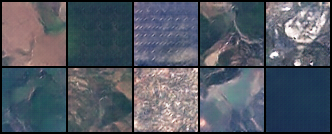

Per-epoch training sample grids saved: 48
Latest per-epoch sample: /content/drive/MyDrive/GeoGen-AI/GeoGen-AI/artifacts/staging/generated/epoch_0050.png


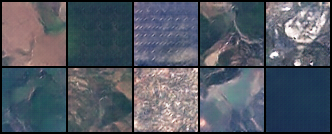

In [ ]:
from IPython.display import display, Image
from torchvision.utils import save_image
from app import load_generator

if not LATEST.is_file():
    raise FileNotFoundError(f'No staged checkpoint found: {LATEST}')
payload = validate_checkpoint(LATEST)
if int(payload['epoch']) != EXPECTED_FINAL_EPOCH:
    raise ValueError(
        f'Staged checkpoint epoch {payload["epoch"]} does not match expected epoch {EXPECTED_FINAL_EPOCH}.'
    )

generator, app_payload, device = load_generator(str(LATEST), LATEST.stat().st_mtime)
assert int(app_payload['epoch']) == EXPECTED_FINAL_EPOCH
print('Staged checkpoint loads through app.py:', LATEST)
print('Completed epoch:', app_payload['epoch'])
print('Staged checkpoint SHA-256:', sha256_file(LATEST))
print('Live demo checkpoint was not replaced:', LIVE_CHECKPOINT)

sample_dir = CHECKPOINT_DIR.parent / 'generated'
sample_dir.mkdir(parents=True, exist_ok=True)
torch.manual_seed(SEED)
sample_labels = torch.arange(len(EXPECTED_CLASSES), device=device)
sample_noise = torch.randn(len(EXPECTED_CLASSES), app_payload['latent_dim'], device=device)
generator.eval()
with torch.no_grad():
    generated = generator(sample_noise, sample_labels).cpu()

validation_sample = sample_dir / f'checkpoint_validation_epoch_{EXPECTED_FINAL_EPOCH:04d}.png'
save_image(generated, validation_sample, nrow=5, normalize=True, value_range=(-1, 1))
print('Saved fixed-seed checkpoint verification grid:', validation_sample)
display(Image(filename=str(validation_sample)))

epoch_samples = sorted(sample_dir.glob('epoch_*.png'))
print(f'Per-epoch training sample grids saved: {len(epoch_samples)}')
if epoch_samples:
    print('Latest per-epoch sample:', epoch_samples[-1])
    display(Image(filename=str(epoch_samples[-1])))

## 9. Download the staged checkpoint for separate review

The downloaded file is from artifacts/staging/checkpoints, not the live demo location. Keep it separate on your laptop while reviewing the sample grids. This notebook contains no step that promotes or overwrites the epoch-2 demo checkpoint.

In [ ]:
from google.colab import files
files.download(str(LATEST))
